# Clasificar el Nivel de Riesgo
Se pretende estimar el riesgo ante una llamada a la línea 144, para esto se utiliza un modelo de Random Forest.

El mótivo de la elección de este modelo, es que el dataset cuenta una gran cantidad de variables *One-Hot*, además de no tener una variable objetivo.

Previamente, el dataset había sido tratado con **Ingenieria de Atributos**, se creó una nueva columna objetivo utilizando una fórmula que le otorgaba un puntaje a dicho campo, que representa el grado de violencia, usando las variables lógicas y categóricas con las que contabamos (las cuáles recibían un peso según su gravedad).

## Importación de Librerias

In [26]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, mean_squared_error, mean_absolute_error, r2_score
import joblib

Se crea una formula que determinara el riesgo de la llamada, y también se recuperara del repositorio de github el dataset procesado.

In [27]:
# Formula para determinar el riesgo de la llamada
def definir_riesgo(row):

    # Criterio de Riesgo Alto (2)
    if (row['tipo_de_violencia_fisica_si'] == 1 or row['tipo_de_violencia_sexual_si'] == 1) and row['vinculo_alto_riesgo'] == 1:
        return 2

    # Criterio de Riesgo Medio (1)
    elif row['score_tipos_violencia'] > 4 or row['score_modalidades_criticas'] > 2:
        return 1

    # Criterio de Riesgo Bajo (0)
    return 0

# Recuperación del dataset procesado
url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/data/processed/dataset_procesado.parquet"
df = pd.read_parquet(url_modelo, engine="pyarrow")

Se crea una nueva variable dentro del dataset procesado con el nivel de riesgo asignado a cada reporte en base a la formula de la anterior celda.

In [28]:
# Llama a la función 'definir_riesgo()' para determinar el riesgo de la llamada
df['nivel_riesgo'] = df.apply(definir_riesgo, axis=1)

# Nos quedamos únicamente con los riesgos Medio (1) y Alto (2)
df = df[df['nivel_riesgo'].isin([1, 2])].copy()

Para evitar el Data Leakage, se excluyen las variables que fueron usadas en la formula matemática en el **Tratamiento**.

También se crea un arreglo con las variables que son realmente importantes para determinar el nivel de riesgo.

In [29]:
# Selección de Features y exclusión de Data Leakage
# Quitamos del mapa las variables que se uso para construir la formula matemática.
columnas_a_excluir = [
    'nivel_riesgo',
    'Fecha',
    'poblacion_provincia',
    'tipo_de_violencia_fisica_si',
    'tipo_de_violencia_sexual_si',
    'vinculo_alto_riesgo',
    'score_tipos_violencia',
    'score_modalidades_criticas',
    'interaccion_gravedad_domestica',
    'pandemia'
]

# Variable objetivo que el modelo debe aprender a predecir
Y_riesgo = df['nivel_riesgo']

# Se disminuye la cantidad de variables a las realmente importantes
features_importantes = [
    'edad_persona_en_situacion_de_violencia',
    'log_pobl_prov',
    'is_weekend',
    'tipo_de_violencia_psicologica_si',
    'tipo_de_violencia_simbolica_si',
    'tipo_de_violencia_economica_y_patrimonial_si',
    'tipo_de_violencia_domestica_si',
    'modalidad_de_violencia_institucional_si',
    'modalidad_de_violencia_laboral_si',
    'modalidad_de_violencia_otras_si',
    'vinculo_con_la_persona_agresora_pareja',
    'vinculo_con_la_persona_agresora_ex pareja',
    'vinculo_con_la_persona_agresora_otro',
    'vinculo_con_la_persona_agresora_otro familiar',
    'genero_persona_en_situacion_de_violencia_mujer',
    'genero_persona_en_situacion_de_violencia_varon',
    'genero_de_la_persona_agresora_varon',
    'genero_de_la_persona_agresora_mujer'
]

Se excluyen los datos que provocan Data Leakage y se particionan los datos (80% Train y 20% Test).

In [30]:
# Guarda en 'X_riesgo' las variables a utilizar.
X_excluidas = df.drop(columns=columnas_a_excluir, errors='ignore')
X_riesgo = X_excluidas[features_importantes].copy()

# Partición de datos - Split (80% entrenamiento y 20% testeo).
X_train, X_test, Y_train, Y_test = train_test_split(
    X_riesgo, Y_riesgo, test_size=0.2, random_state=42, stratify=Y_riesgo
)

Se configura e inicia la búsqueda de hiperparámetros con GridSearchCV para el modelo **Random Forest Classifier**, y al final, se guarda en un joblib el modelo entrenado con los mejores hiperparámetros encontrados.

In [31]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, 15, None],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced']
}

rf_base = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',     # Busca maximizar la métrica 'f1_macro'
    n_jobs=-1
)
grid_search.fit(X_train, Y_train)

best_rf = grid_search.best_estimator_
print(f"\nMejores hiperparámetros encontrados: {grid_search.best_params_}")


Mejores hiperparámetros encontrados: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}


In [32]:
joblib.dump(best_rf, "riesgo.joblib", compress=3)

['riesgo.joblib']

Se comienza a evaluar el modelo **Random Forest Classifier**, lo primero es un reporte de la *precision*, *recall*, *f1-score*, *support* y *accuracy*:

In [33]:
# Predicción y Evaluación del modelo
Y_pred = best_rf.predict(X_test)

print("\n================ REPORTE DE CLASIFICACIÓN ================")
print(classification_report(Y_test, Y_pred, labels=[1, 2], target_names=['Medio', 'Alto']))
print("==========================================================")


================ REPORTE DE CLASIFICACIÓN ================
              precision    recall  f1-score   support

       Medio       0.78      0.57      0.66      6227
        Alto       0.78      0.91      0.84     10749

    accuracy                           0.78     16976
   macro avg       0.78      0.74      0.75     16976
weighted avg       0.78      0.78      0.77     16976



- **Support:** 10,749 casos reales de testeo son de riesgo Alto, y 6,227 de riesgo Medio, sumando un total de 16,976 testeos o evaluaciones.

- **Precision:** Para *Riesgo Alto (0.79)*, de cada 100 casos, el modelo clasificó como "Alto", 79 eran realmente de riesgo alto y 21 fueron falsos positivos.

- **Recall:** De cada 100 casos que eran realmente de riesgo "Alto", el modelo logró identificar correctamente a 91, solo se le escaparon el 9 (falsos negativos), esto quiere decir que 9 de cada 10 llamadas, serán identificados correctamente como "riesgo alto".

- **F1-Score:** Siendo el promedio entre **precision** y **recall**, para riesgo alto dio un puntaje de 0.84, demostrando que el modelo es muy bueno atrapando los casos de riesgo Alto sin equivocarse demasiado.

- **Accuracy:** El modelo acertó en el 78% de todos los casos totales (combinando Medio y Alto).

Se podrá visualizar mejor con la Matriz de Confusión de como el modelo asignó a cada caso en el momento de la prueba:

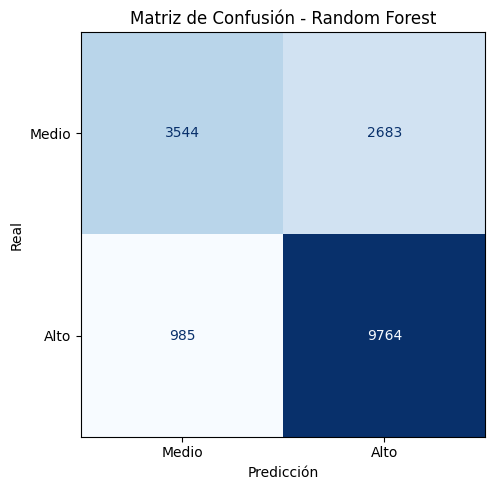

In [34]:
# Matriz de confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, Y_test,
    display_labels=['Medio', 'Alto'],
    cmap='Blues', colorbar=False, ax=ax
)
ax.set(title="Matriz de Confusión - Random Forest", xlabel="Predicción", ylabel="Real")
plt.tight_layout()
plt.savefig('matriz_confusion_rf.png', dpi=300)
plt.show()

El modelo pudo asignar correctamente la mayoría de casos como **"Alto"** (91%), aunque para los casos **Medio** (57%), el modelo tiende a clasificar muchos casos como si fueran "Alto".

Un punto a mejorar sería el **Recall del riesgo Medio (0.57)**, sin embargo, hay que considerar que es preferible que sea asignado como un falso positivo antes que ignorar un peligro real.

Para comprobar que el modelo no memorizo los patrones o no hubo fuga de datos, inspirado en una de las notebooks del campus, se buscara la presencia de overfitting comparado las métricas de **F1-Macro** y **Accuracy**:

In [35]:
# El siguiente DataFrame permite detectar overfitting
resultados_clf = pd.DataFrame({
    "Métrica": ["F1-Macro", "Accuracy"],
    "Entrenamiento": [
        classification_report(Y_train, best_rf.predict(X_train), output_dict=True)['macro avg']['f1-score'],
        best_rf.score(X_train, Y_train)
    ],
    "Prueba": [
        classification_report(Y_test, Y_pred, output_dict=True)['macro avg']['f1-score'],
        best_rf.score(X_test, Y_test)
    ]
})

display(resultados_clf)

,Métrica,Entrenamiento,Prueba
0,F1-Macro,0.785699,0.750425
1,Accuracy,0.813705,0.783930


El overfitting aparece cuándo en el entrenamiento obtiene una nota perfecta, pero fracasa al ser tomado a prueba con datos de testeo
- **F1-Macro**: La diferencia entre el Entrenamiento y la Prueba es de un 3.37%
- **Accuracy**: La diferencia entre el Entrenamiento y la Prueba es de un 2.84%

Como la "caída" entre entrenamiento y prueba es menor que el 4%, el modelo tiene una muy buena capacidad de **generalización** ante nuevas combinaciones de datos que jamas había visto.

La siguiente gráfica muestra las 10 variables/atributos más relevantes durante la asignación de Riesgo de los reportes:


Gráfica de importancia guardada como 'importancia_features_riesgo.png'


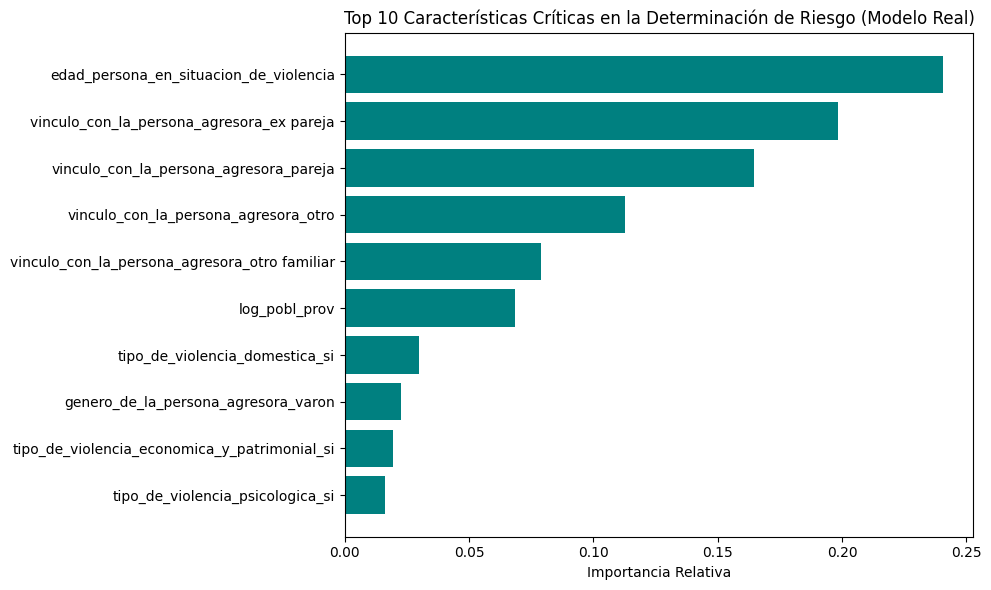

In [36]:
# Gráfica de importancia de variables
importances = best_rf.feature_importances_
indices = np.argsort(importances)[-10:] # Top 10 variables más

plt.figure(figsize=(10, 6))
plt.title("Top 10 Características Críticas en la Determinación de Riesgo (Modelo Real)")
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [X_riesgo.columns[i] for i in indices])
plt.xlabel('Importancia Relativa')
plt.tight_layout()

plt.savefig('importancia_features_riesgo.png', dpi=300)
print("\nGráfica de importancia guardada como 'importancia_features_riesgo.png'")
plt.show()

Domina la **edad de la victima** con casi un 25%, luego los siguientes son los **vinculos** (como con ex-pareja, pareja, otro, familiar), entre otros.

La edad de la victima puede dominar el ranking debido a que su variable continua es el campo con la escala más alta a comparación de los demás utilizados en el entrenamiento del modelo. Aunque la edad pueda ser un importante determinante para la asignación del nivel de riesgo, no podría ser el factor más importante dentro del conjunto de datos.

# Estimar Demanda diaria
Nos pareció acertado al contar con el dataset, utilizarlo para estimar, a través de otro modelo, el volumen de llamadas para una fecha dada.

La posibles utilidades de esta predicción son las siguientes:
- Asignación de recursos
- Refuerzo de personal
- Logística
- Análisis estadístico

Entre otras.

Elegimos XGBoost (eXtreme Gradient Boosting) para estimar la demanda diaria de llamadas (una variable continua) debido a su capacidad excepcional para capturar relaciones no lineales complejas, manejar patrones estacionales y ofrecer una alta velocidad de cómputo en datos estructurados.

A diferencia de los modelos lineales tradicionales, la demanda de llamadas en la línea 144 no se comporta de manera uniforme, está influenciada por picos estacionales, días festivos y variables categóricas complejas.

Se agrupa y ordena por `Fecha`, para después aplicar una ingeniería de atributos temporales donde XGBoost utiliza los días anteriores para predecir el futuro.

In [37]:
# Agrupa por fecha para obtener la cantidad de llamadas diarias.
df_volumen = df.groupby('Fecha').size().reset_index(name='volumen_llamadas')
df_volumen = df_volumen.sort_values('Fecha').reset_index(drop=True)

# Ingeniería de atributos temporales.
df_volumen['dia_semana'] = df_volumen['Fecha'].dt.dayofweek
df_volumen['mes'] = df_volumen['Fecha'].dt.month
df_volumen['dia'] = df_volumen['Fecha'].dt.day

# Crear rezagados (lags features): Volumen de días anteriores para predecir el futuro.
df_volumen['lag_1'] = df_volumen['volumen_llamadas'].shift(1)  # Día anterior
df_volumen['lag_7'] = df_volumen['volumen_llamadas'].shift(7)  # Semana anterior

# Elimina valores nulos generados por los lags.
df_volumen = df_volumen.dropna().reset_index(drop=True)

Se particionan los datos (80% Train del pasado y 20% Test del futuro).

In [38]:
# Se definen los Features (X) y Target (Y).
features_volumen = ['dia_semana', 'mes', 'dia', 'lag_1', 'lag_7']
X_vol = df_volumen[features_volumen]
Y_vol = df_volumen['volumen_llamadas']

# Partición cronológica (80% pasado para entrenar, 20% futuro para testear)
train_size = int(len(X_vol) * 0.8)
X_train_vol, X_test_vol = X_vol.iloc[:train_size], X_vol.iloc[train_size:]
Y_train_vol, Y_test_vol = Y_vol.iloc[:train_size], Y_vol.iloc[train_size:]

Se configura e inicia la búsqueda de hiperparámetros con GridSearchCV para el modelo **XGBoost**, y al final, se guarda en un joblib, el modelo entrenado con los mejores hiperparámetros encontrados.

In [39]:
# Se prepara GridSearchCV para entrenar XGBoost Regressor
print("Iniciando GridSearchCV para XGBoost Regressor...")
param_grid_xgb = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.01, 0.1]
}

xgb_base = XGBRegressor(random_state=42, n_jobs=-1)

# TimeSeriesSplit respeta el orden temporal para la validación cruzada
tscv = TimeSeriesSplit(n_splits=3)

grid_search_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    cv=tscv,
    scoring='neg_mean_absolute_error', # Mide el error absoluto medio negativo
    n_jobs=-1
)
grid_search_xgb.fit(X_train_vol, Y_train_vol)

best_xgb_reg = grid_search_xgb.best_estimator_
print(f"\nMejores parámetros encontrados para XGBoost: {grid_search_xgb.best_params_}")

Iniciando GridSearchCV para XGBoost Regressor...

Mejores parámetros encontrados para XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}


In [40]:
joblib.dump(best_xgb_reg, "volumen.joblib", compress=3)

['volumen.joblib']

Se comienza a evaluar el modelo **XGBoost Regressor**, lo primero es un reporte de *MAE*, *RMSE*, y *R²*:

In [41]:
# Predicción y Evaluación
Y_pred_vol = best_xgb_reg.predict(X_test_vol)

mae = mean_absolute_error(Y_test_vol, Y_pred_vol)
rmse = np.sqrt(mean_squared_error(Y_test_vol, Y_pred_vol))
r2 = r2_score(Y_test_vol, Y_pred_vol)

print("\n================ EVALUACIÓN DE PREDICCIÓN DE VOLUMEN ==================")
print(f"MAE (Error Absoluto Medio): {mae:.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.2f}")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print("========================================================================")


================ EVALUACIÓN DE PREDICCIÓN DE VOLUMEN ==================
MAE (Error Absoluto Medio): 9.22
RMSE (Raíz del Error Cuadrático Medio): 11.25
R² (Coeficiente de Determinación): -0.1467


- **MAE:** Quiere decir que el modelo en las predicciones se equivocan por 9 llamadas (promedio, hacia arriba o abajo) respecto al volumen real diario.

- **RMSE:** Al ser 11.25, es un valor cercano al MAE (9.22), donde los errores son relativamente constantes, ya que RMSE castiga con mucha fuerza los errores grandes.

- **R²:** Aca hay un caso negativo, hubo un resultado de -0.1467, quiere decir que el modelo XGBoost predice peor que promediar las llamadas de todos los días y usar ese resultado.

Esto último es debido a un sobreajuste, memorizando patrones específicos de los datos de entrenamiento que no se replican en los datos de prueba.
Se compararan las métricas en el entrenamiento y el testeo para entender el comportamiento de las métricas:

In [42]:
# Comparación de las métricas
y_train_pred_vol = best_xgb_reg.predict(X_train_vol)

# Tabla comparativa de entrenamiento vs prueba (Inspirado en la Sección 6 de la notebook)
resultados_volumen = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Entrenamiento": [
        mean_absolute_error(Y_train_vol, y_train_pred_vol),
        np.sqrt(mean_squared_error(Y_train_vol, y_train_pred_vol)),
        r2_score(Y_train_vol, y_train_pred_vol)
    ],
    "Prueba": [
        mae,
        rmse,
        r2
    ]
})

print("\nResumen Comparativo (Entrenamiento vs. Prueba):")
display(resultados_volumen.round(3))


Resumen Comparativo (Entrenamiento vs. Prueba):


,Métrica,Entrenamiento,Prueba
0,MAE,8.111,9.223
1,RMSE,10.495,11.251
2,R²,0.560,-0.147


- En **MAE** como en **RMSE**, aumenta el error un poco, apróximadamente una llamada más de error en *Prueba*.

- En R², el modelo logra explicar el 56% de la variabilidad de los datos, es aceptable aunque haya sido capaz de encontrar reglas y tendencias lógicas para predecir las llamadas. Pero, en el momento de la prueba, obtuvo un puntaje negativo (-0.147) al estar de frente a nuevos días, donde las reglas que aprendió fallan en las predicciones, esto puede deberse a overfitting y habría que regularizar los hiperparámetros.

Para explicar mejor sobre el caso de R² negativo, se mostrara una gráfica que compara los datos reales y los predichos:

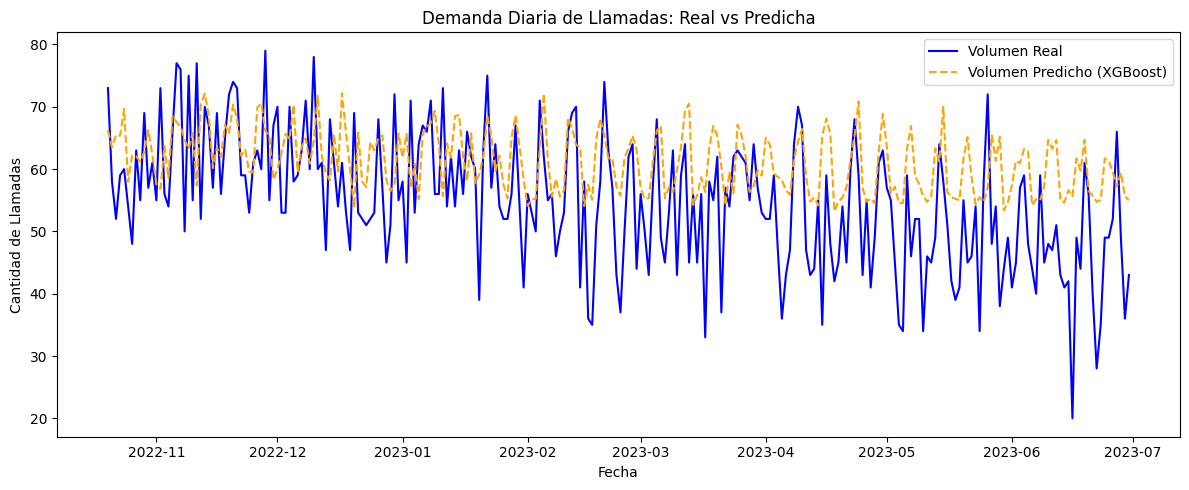

In [43]:
plt.figure(figsize=(12, 5))
plt.plot(df_volumen['Fecha'].iloc[train_size:], Y_test_vol, label='Volumen Real', color='blue')
plt.plot(df_volumen['Fecha'].iloc[train_size:], Y_pred_vol, label='Volumen Predicho (XGBoost)', color='orange', linestyle='--')
plt.title('Demanda Diaria de Llamadas: Real vs Predicha')
plt.xlabel('Fecha')
plt.ylabel('Cantidad de Llamadas')
plt.legend()
plt.tight_layout()
plt.savefig('prediccion_volumen_llamadas.png', dpi=300)
plt.show()

El volumen Real es de color azul, mientras que el Predicho es el de naranja, y gracias a esta gráfica, se revelan otros hallazgos sobre el comportamiento del modelo:
- En la línea azul desde finales de 2022 hasta mediados de 2023, la demanda real va en bajada, rondando de unos 50-80 llamadas a unos 30-70, esto querrá decir que durante 2023, este dataset, muestra como la demanda diaria de llamadas de la línea 144 estuvo disminuyendo.

- La línea naranja se mantiene en su promedio original, alrededor de unas 60 llamadas, incapaz de notar que el comportamiento de las llamadas esta disminuyendo con los meses, estimando que habrá muchas más llamadas de las que realmente ocurren.

Aunque el modelo es acertivo al principio del periodo, conforme pasa el tiempo, el modelo se vuelve cada vez peor, siendo incapaz de adaptarse a la tendencia decrediente de los datos históricos.


# Persistencia de los Modelos

In [44]:
# Definir la URL directa del archivo .joblib o .pkl
url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/modelos/riesgo.joblib"

# Descargar el archivo binario
respuesta = requests.get(url_modelo)
respuesta.raise_for_status()  # Lanza un error si la descarga falla

In [45]:
# Definir la URL directa del archivo .joblib o .pkl
url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/modelos/volumen.joblib"

# Descargar el archivo binario
respuesta = requests.get(url_modelo)
respuesta.raise_for_status()  # Lanza un error si la descarga falla

# **Conclusión**
En el proyecto de análisis de los reportes de la Línea 144, se implementó dos enfoques para abordar dos dimensiones del servicio:

## Clasificación de Riesgo
Se entrenó un modelo de **Random Forest Classifier** para predecir el nivel de riesgo (*Medio* o *Alto*) de los reportes, priorizando la detección de llamadas de riesgo *Alto*, como así también los casos de Falso Positivo, diseñando una función objetivo en base a una formula excluyendo las variables que podrían causar Data Leakage.

El modelo alcanzó un **Accuracy del 78%**, demostrando un rendimiento sólido y equilibrado, con un **Recall de 0.91** y una **Precisión de 0.79** para la clase *Alto* (F1-score de 0.84), indica que el modelo e altamente eficaz identificado 9 de cada 10 llamadas de riesgo alto.

Aunque el *Recall* del riesgo *Medio* se ubicó en 0.57, ya que el modelo tiende a sobreestimar algunos casos hacía la otra categoría, de igual forma, se concluye que este sesgo es deseable, priorizando los casos de falso positivo antes que omitir un peligro real.

También la validación entre el entrenamiento y la prueba demostró una pequeña caída menor al 4% (**F1-Macro** pasó de 0.78 a 0.75), esto confirma que el modelo no presenta overfitting, y posee una muy buena capacidad de generalización ante nuevos datos.

---
## Predicción de Demanda
Se implementó un modelo de XGBoost Regressor con el objetivo de anticipar el volumen diario de llamadas para la gestión de recursos operativos.

Los resultados de la evaluación demostraron un **MAE de 9.22** llamadas por día, y un **RMSE de 11.25**, lo que evidencia un error constante en la escala diaria.

Sin embargo, el **R² de -0.1468** indica un rendimiento deficiente en términos de variabilidad, estimando peor que la media histórica, revelando overfitting o que las características actuales no son suficientes para capturar la demanda diaria.

---
## Reflexión y Limitaciones
- La curación, la exclusión de variables para evitar data leakage y la optimización de hiperparámetros mediante **GridSearchCV** permitieron construir un clasificador de riesgo sólido y preparado para su persistencia mediante **joblib (`riesgo.joblib`)**.

- El modelo de XGBoost necesita ajustes en sus hiperparámetros, un análisis más profundo en la ingeniería de atributos temporales (por ejemplo, agregar si hubo feriados o tener en cuenta el tiempo atmosférico), debido a su overfitting, o incluso regesar una etapa atrás para volver tratar el dataset. De esta manera se podría corregir el coeficiente de terminación negativo (R² < 0) y lograr capturar la frecuencia de demandas.

---
## Próximos Pasos y Posibles Mejoras
- Se desplegara el modelo sobre el **Clasificador de Riesgo** entrenado de Random Forest en una API, para que el sistema de la Línea 144 pueda evaluar el riesgo de manera rápida (o automatizada).

- Se reestructurará el dataset de series temporales para el XGBoost analizando los hiperparámetros y sus variables utilizadas que expliquen mejor la variabilidad diaria.